In [4]:
# 作业1：Significant earthquakes since 2150 B.C.

# 声明引入需要用到的库
import pandas as pd
import matplotlib.pyplot as plt

# 导入已经下载好的Sig_Eqs.tsv数据，tsv文件使用制表符分隔
Sig_Eqs = pd.read_csv("Sig_Eqs.tsv", sep="\t")
# 清除没有Id的数据，如文件第一行是查询信息，没有 Id，不属于地震记录
Sig_Eqs = Sig_Eqs.dropna(subset=["Id"]).copy()
# 查看一下需要计算的几列数据的数据类型是否是数字，不能是文本，再检查一下头几行
print(Sig_Eqs[["Year","Mo","Dy","Ms","Mag","Deaths"]].dtypes)
# 将核验过的Year字段转为整数
Sig_Eqs["Year"] = Sig_Eqs["Year"].astype(int)
print("数据形状：", Sig_Eqs.shape)
Sig_Eqs.head(10)

Year      float64
Mo        float64
Dy        float64
Ms        float64
Mag       float64
Deaths    float64
dtype: object
数据形状： (6697, 49)


,Search Parameters,Id,Year,Mo,Dy,Hr,Mn,Sec,Tsu,Vol,...,Total Missing,Total Missing Description,Total Injuries,Total Injuries Description,Total Damage ($Mil),Total Damage Description,Total Houses Destroyed,Total Houses Destroyed Description,Total Houses Damaged,Total Houses Damaged Description
1,NaN,1.0,-2150,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,2.0,-2000,NaN,NaN,NaN,NaN,NaN,1.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,3.0,-2000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,1.0,NaN,1.0,NaN,NaN
4,NaN,5877.0,-1610,NaN,NaN,NaN,NaN,NaN,3.0,1351.0,...,NaN,NaN,NaN,NaN,NaN,3.0,NaN,NaN,NaN,NaN
5,NaN,8.0,-1566,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,NaN,11.0,-1450,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,NaN,9712.0,-1365,NaN,NaN,NaN,NaN,NaN,4.0,NaN,...,NaN,NaN,NaN,NaN,NaN,3.0,NaN,NaN,NaN,NaN
8,NaN,12.0,-1250,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,NaN,13.0,-1050,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10,NaN,14.0,-759,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,3.0,NaN,NaN,NaN,NaN


In [3]:
# 题目1.1：统计各国公元前2150年以来死亡人数，并排序输出

# 按Country列分组，对Deaths求和，设置min_count=1——如果一个国家的Deaths全部缺失，结果仍为缺失值而不是0
deaths_by_country = Sig_Eqs.groupby("Country")["Deaths"].sum(min_count=1)
# 按死亡人数降序排列，取前30名
top20 = deaths_by_country.sort_values(ascending=False).head(30)
# 使用整数格式显示人数
print(top20.astype("Int64").to_string())

Country
CHINA           2139209
TURKEY          1199720
IRAN            1014453
ITALY            492236
SYRIA            419826
HAITI            323484
AZERBAIJAN       319251
JAPAN            242516
ARMENIA          177890
PAKISTAN         145085
IRAQ             136200
ECUADOR          135496
TURKMENISTAN     117412
PERU             102309
ISRAEL            93388
PORTUGAL          83572
GREECE            81162
CHILE             64277
INDIA             63507
TAIWAN            57154
VENEZUELA         51189
TUNISIA           48013
EGYPT             41765
INDONESIA         41458
ALGERIA           39339
LEBANON           30208
GUATEMALA         28826
ARGENTINA         24568
MOROCCO           22775
NEPAL             21619


Ms大于3.0的地震记录总数： 3101
各年的地震记录数量：
Year
-2150    0
-2149    0
-2148    0
-2147    0
-2146    0
        ..
 2022    0
 2023    0
 2024    1
 2025    3
 2026    0
Name: CountEq, Length: 4176, dtype: int64


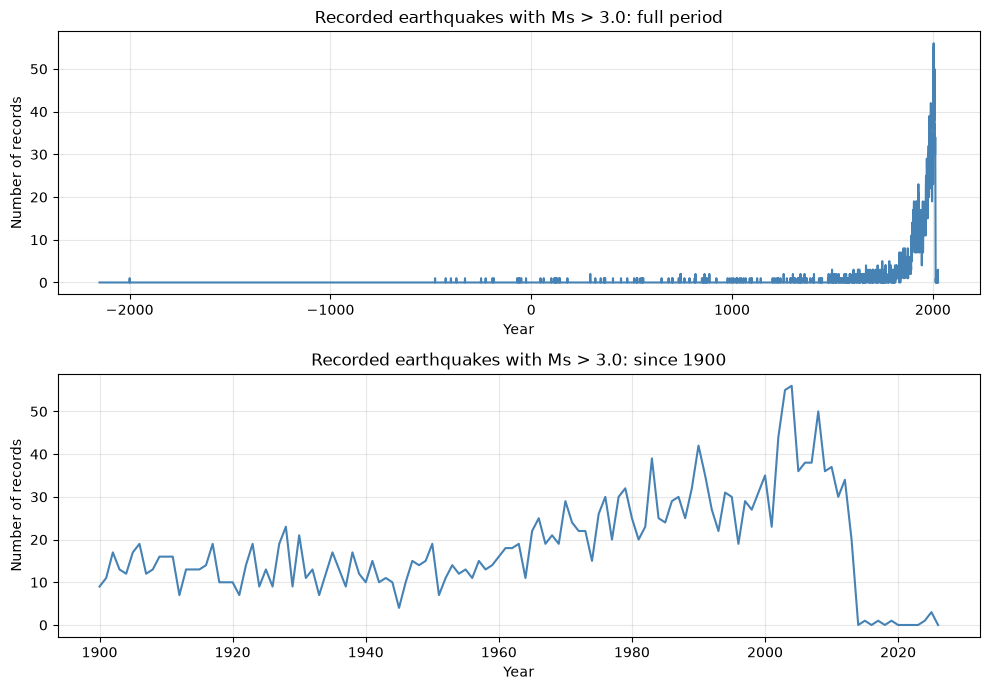

In [18]:
# 题目1.2：统计全球每年Ms大于3.0的地震记录数，并绘制时间序列

# 第一步：筛选符合条件的地震
# 用Sig_Eqs["Ms"]>3.0逐行判断震级是否大于3.0，随后外层Sig_Eqs[...]只保留符合条件的数据行
# Ms这一列缺失的记录不会被选中
selected = Sig_Eqs[Sig_Eqs["Ms"] > 3.0]

# 第二步：按年份统计数量
# 用groupby("Year")将同一年发生的地震分为一组，再使用size()来统计每组的行数，即该年的地震记录数量，最后用sort_index()按照年份从早到晚排列
annual_counts = selected.groupby("Year").size().sort_index()

# 第三步：因为之前的筛选会有年份缺失，这里补齐年份，让折线图包含完整的年份范围
# 先确定整个数据表的年份范围
start_year = Sig_Eqs["Year"].min()
end_year = Sig_Eqs["Year"].max()
# 用for循环把每一个年份放进years列表里，负数年份表示公元前
# 因为历史纪年中没有公元0年，所以数到0的时候跳过
years = [
    year
    for year in range(start_year, end_year + 1)
    if year != 0
]
# 此时annual_counts前面是groupby出来的Series，其索引是年份，而且是有Ms>3.0记录的年份才在里面
# 因此使用.reindex(years)强制让这个Series的索引变成刚造好的完整年份列表years
# 如果某个年份原本不存在Ms>3.0的地震，就用fill_value=0填充该年份的记录
annual_counts = annual_counts.reindex(years, fill_value=0)
# 命名一下方便理解
annual_counts.index.name = "Year"
annual_counts.name = "CountEq"
# 输出一下结果看一下
print("Ms大于3.0的地震记录总数：",len(selected))
print("各年的地震记录数量：")
print(annual_counts)
# annual_counts.tail(30)

# 第四步：绘制时间序列
# 创建一个画布fig，里面有一个两行一列的子图数组axes，figsize=(10,7)设置整张图片的宽度和高度
fig, axes = plt.subplots(2, 1,figsize=(10,7))

# 上图画的是所有年份的震级Ms>3.0的地震数量时间序列
annual_counts.plot(ax=axes[0], color="steelblue")
axes[0].set_title("Recorded earthquakes with Ms > 3.0: full period")

# 下图是选取了1900年及以后的数据时间序列图，方便观察近期变化（波动也更丰富）
annual_counts.loc[1900:].plot(ax=axes[1], color="steelblue")
axes[1].set_title("Recorded earthquakes with Ms > 3.0: since 1900")

# 给两幅图分别添加坐标轴名称和网格线
for ax in axes:
    ax.set_xlabel("Year")
    ax.set_ylabel("Number of records")
    ax.grid(alpha=0.3)
# 自动调整图与图之间的距离，避免文字重叠
plt.tight_layout()
plt.show()

# 趋势分析：
# 从图中可以看到，早期记录较少，近现代记录总体增多，尤其在20世纪后半叶至2000年代较多，但年度之间存在明显波动。
# 但总体而言我认为无法论断存在明显的趋势，首先该数据库主要收录具有重大影响的地震，例如造成死亡、较大损失或引发海啸的事件，并不是全球所有3.0级以上地震的完整目录。
# 其次已有数据存在大量缺测，NOAA数据库也说明了“2014年以后曲线骤降，尤其需要结合缺失值解释”。
# 例如，2014年有56条地震记录，但全部缺少Ms；2026年的19条记录也全部缺少Ms，且2026年尚未结束。
# 因此，真实情况的完整性有待补充，也不能据目前的数据判断2014年之后真实地震活动显著减少。

In [19]:
# 题目1.3：编写函数，返回各国家的地震总数及最大地震的日期、地点，并按总数降序排列

# 将年月日3列数据取出先转成整形数字，空数据NaN日期使用“未知”进行填充
date_parts = Sig_Eqs[["Year", "Mo", "Dy"]].astype("Int64")
date_parts = date_parts.astype("string").fillna("??")
# 将刚刚处理好的年月日3列数据拼接成YYYY-MM-DD格式的字符串日期，放在新建一列的"Date"数据中
Sig_Eqs["Date"] = (
    date_parts["Year"] + "-"
    + date_parts["Mo"].str.zfill(2) + "-"
    + date_parts["Dy"].str.zfill(2)
)

# 编写指定函数，返回指定国家的地震总数，以及最大已知 Ms 对应的日期和地点。
def CountEq_LargestEq(country):
    # 筛选出指定国家的所有地震数据记录
    country_data = Sig_Eqs[Sig_Eqs["Country"] == country]
    # 统计包含该国家的全部地震记录的数量
    count_eq = len(country_data)
    # 依旧使用“Ms”列震级数据作为衡量地震大小的标准，选出该国家发生过的最大地震记录
    max_ms = country_data["Ms"].max()
    # 筛选出最大Ms对应的记录，分别保留日期和地点两列，如果有多条记录并列最大，就全部保留，每条记录单独占一行
    largest = country_data.loc[
        country_data["Ms"] == max_ms,
        ["Date", "Location Name"]
    ].copy()

    # 如果该国家的Ms全部缺失，就无法确定最大地震，故输出的结果中用pd.NA将日期和地点标记为未知
    if largest.empty:
        largest = pd.DataFrame({
            "Date": [pd.NA],
            "Location Name": [pd.NA]
        })
    # 接着为结果添加国家名、地震总数和最大Ms，如果没有Ms数据则为NaN
    largest["Country"] = country
    largest["CountEq"] = count_eq
    largest["LargestMs"] = max_ms
    # 按顺序返回各列
    return largest[
        ["Country", "CountEq", "LargestMs", "Date", "Location Name"]
    ]


# 用列表保存每个国家的结果
country_results = []
# 使用for循环对每个国家都调用一次CountEq_LargestEq()函数
for country in Sig_Eqs["Country"].unique():
    country_results.append(CountEq_LargestEq(country))
# 每次调用函数会返回一个小表，使用concat将这些小表按行进行合并，ignore_index=True重新编排行索引
result = pd.concat(country_results, ignore_index=True)
# 按地震总数降序排列，数量相同时按国家名排序
result = result.sort_values(
    ["CountEq", "Country"],
    ascending=[False, True]
)
# 输出时隐藏左侧的行索引
result.style.hide(axis="index")
# 特别注明：例如JAPAN这种会在结果中输出两行数据的诸多国家，原因是该国家最大的有记录的地震震级（Ms_Max)存在相同的多个，因此一起输出

Country,CountEq,LargestMs,Date,Location Name
CHINA,626,8.600000,1920-12-16,"CHINA: GANSU PROVINCE, SHANXI PROVINCE"
JAPAN,429,8.600000,869-07-13,JAPAN: SANRIKU
JAPAN,429,8.600000,887-08-26,JAPAN: NANKAIDO
INDONESIA,427,8.800000,2004-12-26,INDONESIA: SUMATRA: ACEH: OFF WEST COAST
IRAN,385,7.900000,856-12-22,"IRAN: DAMGHAN, QUMIS"
TURKEY,359,7.800000,1939-12-26,TURKEY: ERZINCAN
TURKEY,359,7.800000,1999-08-17,"TURKEY: ISTANBUL, KOCAELI, SAKARYA"
ITALY,338,7.500000,1915-01-13,"ITALY: MARSICA, AVEZZANO, ABRUZZI"
GREECE,296,8.000000,365-07-21,GREECE: CRETE: KNOSSOS
GREECE,296,8.000000,1303-08-08,GREECE: CRETE
